---
---

<h1><center><ins>Exercise Sheet 5</ins></center></h1>
<h2><center>Numerical Methods <br>

---
---

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from numpy.polynomial.legendre import leggauss
from numpy import exp, cos

## Exercise 1 - Numerical derivative

**(A)** Compute the derivative of the following two functions:

$$ f_1(x) = x^2 + \cos(x) $$

$$ f_2(x) = \exp(x) - x^3 $$

in correspondence of at least $N = 50$ values $x_i$ ($i = 1, ..., N$) of the variable $x$ in the interval $[1,5]$. To do this, *write your own code to compute the derivatives numerically*.

**(B)** Compare the resulting values you get for the numerical derivatives with the corresponding analytic solutions. Calculate the value of the quantity $q$ for each function:

$$ q = \sum_{i=1}^N \frac{\left[d_i - f'(x_i) \right]}{f'(x_i)} $$

where $d_i$ are the values you obtained for the numerical derivatives for each of the $N$ abscissas, and $f'(x_i)$ are the analytical derivatives evaluated in points $x_i$. How does the value of $q$ change when changing the value of $h$ to compute the derivatives numerically? How do the values of $q$ compare for the two functions? Discuss your findings.

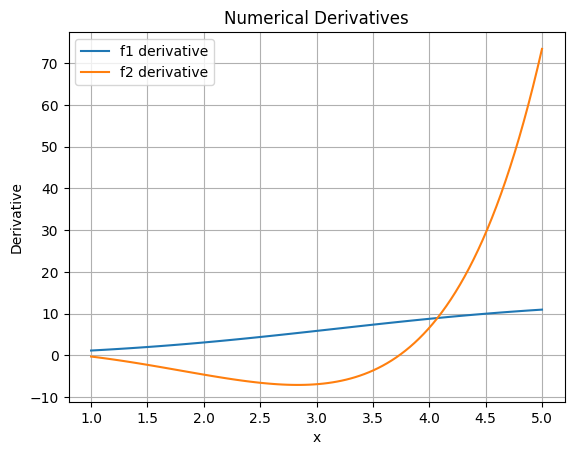

In [12]:
#a
def f1(x):
    return x**2 + np.cos(x)
def f2(x):
    return np.exp(x) - x**3
x = np.linspace(1, 5, 100)
h = 0.001
df1 = (f1(x + h) - f1(x - h)) / (2*h)
df2 = (f2(x + h) - f2(x - h)) / (2*h)
plt.plot(x, df1, label="f1 derivative")
plt.plot(x, df2, label="f2 derivative")
plt.xlabel("x")
plt.ylabel("Derivative")
plt.title("Numerical Derivatives")
plt.legend()
plt.grid()
plt.show()

In [3]:
#b
# Analytical derivatives
def df1_analytic(x):
    return 2*x - np.sin(x)
def df2_analytic(x):
    return np.exp(x) - 3*x**2
h_values = [0.1, 0.01, 0.001, 0.0001]
for h in h_values:
    df1_num = (f1(x+h) - f1(x-h)) / (2*h)
    df2_num = (f2(x+h) - f2(x-h)) / (2*h)
    df1_an = df1_analytic(x)
    df2_an = df2_analytic(x)
    q1 = np.sum((df1_num - df1_an) / df1_an)
    q2 = np.sum((df2_num - df2_an) / df2_an)
    print(f"h = {h}: q1 = {q1:.6f}, q2 = {q2:.6f}")

h = 0.1: q1 = 0.021546, q2 = 0.231341
h = 0.01: q1 = 0.000216, q2 = 0.002313
h = 0.001: q1 = 0.000002, q2 = 0.000023
h = 0.0001: q1 = 0.000000, q2 = 0.000000


## Exercise 2 - Newton-Cotes formulas

In the file ```surface_luminosity.txt``` you will find the numerical function describing the surface luminosity $\Sigma$ of a globular star cluster as a function of the distance $R$ from its centre (projected on the plane of the sky). Compute the total luminosity $L$ of the system by performing the integral

$$ L = \int_0^{R_{\text{max}}} \Sigma(R) \, 2 \pi R \, dR $$

using the trapezoid rule and Simpson's rule, and compare the results you obtain. To do this, first choose one of these methods and implement **your own algorithm to compute the integral with it**; for the other method, use the corresponding built-in python function ```scipy.integrate.trapz``` or ```scipy.integrate.simps``` and familiarize on its usage.

In [4]:
data = np.loadtxt("surface_luminosity.txt")
R = data[:, 0]
Sigma = data[:, 1]
f = 2 * np.pi * R * Sigma
L_trap = 0
for i in range(len(R) - 1):
    h = R[i+1] - R[i]
    L_trap += h * (f[i] + f[i+1]) / 2
L_simp = simpson(f, x=R)
print("Trapezoidal rule:", L_trap)
print("Simpson's rule:", L_simp)
print("Difference:", abs(L_trap - L_simp))

Trapezoidal rule: 1285408.7095045173
Simpson's rule: 1282549.6319938095
Difference: 2859.077510707779


## Exercise 3 - Gaussian Quadrature

**(A)** Compute the following integral by using a 4-point Gaussian quadrature. 

$$ I = \int_{-1}^{1} \cos(x) dx $$

To do this, use the Legendre polynomial of degree 4:

$$ P_4(x) = \frac{1}{8}(35 x^4 - 30 x^2 +3) $$

At this link: https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature you can find the roots of Legendre polynomials and the necessary weights to solve the integral (i.e., you do not have to calculate them all from scratch!).

**(B)** Compare the result with the ones you obtain when using a Legendre polynomial of degree 3, 2, and 1, and comment your findings.

In [5]:
#a
import numpy as np
x = [-0.8611363116, -0.3399810436,
      0.3399810436,  0.8611363116]
w = [0.3478548451, 0.6521451549,
     0.6521451549, 0.3478548451]
I = 0
for i in range(4):
    I += w[i] * np.cos(x[i])
I_exact = 2 * np.sin(1)
print("Gaussian quadrature:", I)
print("Analytical solution:", I_exact)
print("Absolute error:", abs(I - I_exact))

Gaussian quadrature: 1.68294168870806
Analytical solution: 1.682941969615793
Absolute error: 2.809077330745424e-07


In [6]:
#b
import numpy as np
from numpy.polynomial.legendre import leggauss
I_exact = 2 * np.sin(1)
for n in [1, 2, 3, 4]:
    x, w = leggauss(n)
    I = np.sum(w * np.cos(x))
    error = abs(I - I_exact)
    print(f"Degree {n}: I = {I:.8f}, Error = {error:.8f}")

Degree 1: I = 2.00000000, Error = 0.31705803
Degree 2: I = 1.67582366, Error = 0.00711831
Degree 3: I = 1.68300355, Error = 0.00006158
Degree 4: I = 1.68294169, Error = 0.00000028


## Exercise 4 - Monte Carlo integration 

Consider the following integral:
$$ I = \int_0^1 \cos \left(\frac{\pi x}{2} \right) dx = \frac{2}{\pi} $$

**(A)** Compute the above integral and its variance by using the following Monte Carlo methods:

1. mean value

How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.



In [7]:
#a
import numpy as np
def f(x):
    return np.cos(np.pi * x / 2)
N = 10000
x = np.random.uniform(0, 1, N)
y = f(x)
I = np.mean(y)
variance = np.var(y, ddof=1) / N
I_exact = 2 / np.pi
print("Monte Carlo integral:", I)
print("Variance:", variance)
print("Analytical solution:", I_exact)
print("Absolute error:", abs(I - I_exact))

Monte Carlo integral: 0.62964972658707
Variance: 9.583868960457526e-06
Analytical solution: 0.6366197723675814
Absolute error: 0.0069700457805114135


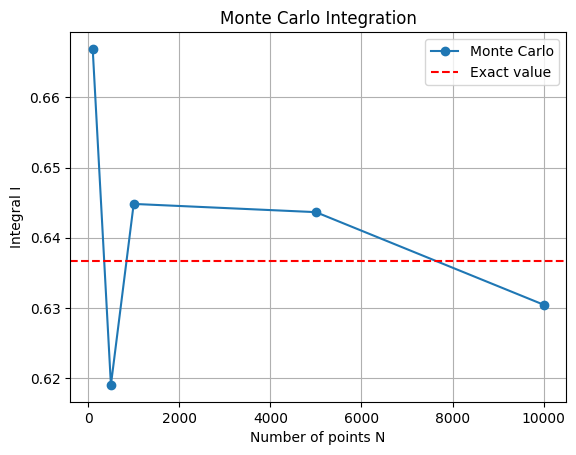

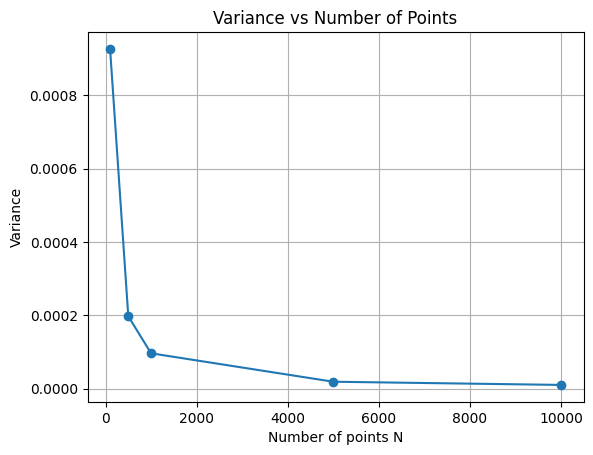

In [8]:
import matplotlib.pyplot as plt
N_values = [100, 500, 1000, 5000, 10000]
I_values = []
variance_values = []
for N in N_values:
    x = np.random.uniform(0, 1, N)
    y = np.cos(np.pi * x / 2)
    I = np.mean(y)
    variance = np.var(y, ddof=1) / N
    I_values.append(I)
    variance_values.append(variance)
I_exact = 2 / np.pi

plt.figure()
plt.plot(N_values, I_values, 'o-', label="Monte Carlo")
plt.axhline(I_exact, color='red', linestyle='--', label="Exact value")
plt.xlabel("Number of points N")
plt.ylabel("Integral I")
plt.title("Monte Carlo Integration")
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.plot(N_values, variance_values, 'o-')
plt.xlabel("Number of points N")
plt.ylabel("Variance")
plt.title("Variance vs Number of Points")
plt.grid()
plt.show()

## Exercise 5 - Monte Carlo integration continued (optional)

**(A)** Compute the above integral from Exercise 4 and its variance by using the other Monte Carlo methods covered in the lecture:

2. Importance sampling

Hint: for importance sampling, you can use the following weight function: 
$$w(x) = A \frac{1}{1+\left( \pi x/2 \right)^2}$$
where you can determine the normalization constant by imposing:
$$\int_0^1 w(x) dx = 1 = A \frac{2}{\pi} \arctan(\pi/2) \rightarrow A = \frac{\pi}{2 \arctan(\pi/2)}$$


How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.

In [9]:
#a
import numpy as np
def f(x):
    return np.cos(np.pi * x / 2)
A = np.pi / (2 * np.arctan(np.pi / 2))
def w(x):
    return A / (1 + (np.pi * x / 2)**2)
N = 10000
u = np.random.uniform(0, 1, N)
x = (2 / np.pi) * np.tan(u * np.arctan(np.pi / 2))
y = f(x) / w(x)
I = np.mean(y)
variance = np.var(y, ddof=1) / N
I_exact = 2 / np.pi

print("Importance sampling:", I)
print("Variance:", variance)
print("Analytical solution:", I_exact)
print("Absolute error:", abs(I - I_exact))

Importance sampling: 0.6380035214497415
Variance: 1.680110921172754e-06
Analytical solution: 0.6366197723675814
Absolute error: 0.0013837490821601017


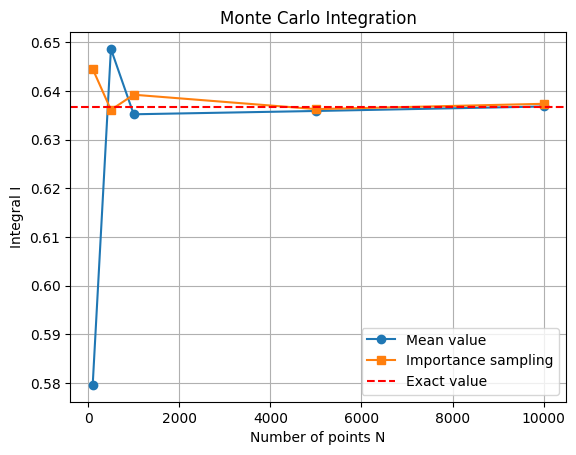

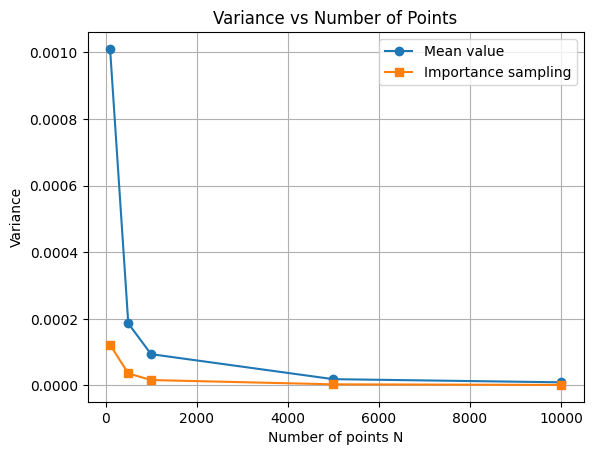

In [10]:
#b
import numpy as np
import matplotlib.pyplot as plt
def f(x):
    return np.cos(np.pi * x / 2)
A = np.pi / (2 * np.arctan(np.pi / 2))
def w(x):
    return A / (1 + (np.pi * x / 2)**2)
N_values = [100, 500, 1000, 5000, 10000]
I_mean = []
I_importance = []
var_mean = []
var_importance = []
for N in N_values:
    x1 = np.random.uniform(0, 1, N)
    y1 = f(x1)
    I_mean.append(np.mean(y1))
    var_mean.append(np.var(y1, ddof=1) / N)
    u = np.random.uniform(0, 1, N)
    x2 = (2 / np.pi) * np.tan(u * np.arctan(np.pi / 2))
    y2 = f(x2) / w(x2)
    I_importance.append(np.mean(y2))
    var_importance.append(np.var(y2, ddof=1) / N)
I_exact = 2 / np.pi
plt.figure()
plt.plot(N_values, I_mean, 'o-', label="Mean value")
plt.plot(N_values, I_importance, 's-', label="Importance sampling")
plt.axhline(I_exact, color='red', linestyle='--', label="Exact value")

plt.xlabel("Number of points N")
plt.ylabel("Integral I")
plt.title("Monte Carlo Integration")
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.plot(N_values, var_mean, 'o-', label="Mean value")
plt.plot(N_values, var_importance, 's-', label="Importance sampling")

plt.xlabel("Number of points N")
plt.ylabel("Variance")
plt.title("Variance vs Number of Points")
plt.legend()
plt.grid()
plt.show()